### All imports

In [1]:
!pip install control
import control as ct

from IPython.display import clear_output
clear_output()

In [2]:
import numpy as np

from sympy import symbols, rad, solve, lambdify, Matrix, matrix2numpy
from sympy.physics.mechanics import ReferenceFrame, dynamicsymbols

from scipy.integrate import odeint

from matplotlib import pyplot as plt

from matplotlib.animation import FFMpegWriter
from IPython.display import Image

### Kinematics

In [3]:
x_1, x_2, theta = dynamicsymbols('x_1, x_2, theta')
u_1, u_2 = symbols('u_1, u_2')

N = ReferenceFrame('N')

B = N.orientnew('B', 'Axis', (theta, N.z))
M = B.orientnew('M', 'Axis', (rad(90) + u_2, B.z))

In [4]:
l_motor, m_motor, l_battery, m_battery = symbols('l_motor, m_motor, l_battery, m_battery')

boat_xpos = x_1*N.x + x_2*N.y
motor_pos = -l_motor*B.y
battery_pos = l_battery*B.y

boat_com = ((battery_pos*m_battery + motor_pos*m_motor)/(m_battery + m_motor))

boat_xipos = boat_xpos + boat_com
boat_xivel = boat_xipos.dt(N)
boat_xiacc = boat_xivel.dt(N)


### Kinetics

In [5]:
c = symbols('c')

sumF = u_1*M.x -c*(boat_xivel) - (m_motor + m_battery)*boat_xiacc

I = m_motor*((motor_pos - boat_com).magnitude())**2 + m_battery*((battery_pos - boat_com).magnitude())**2

sumM = (motor_pos - boat_com).cross(u_1*M.x) -c*theta.diff()*B.z - I*theta.diff().diff()*B.z


In [6]:
sumFx = sumF.dot(N.x)
sumFy = sumF.dot(N.y)
sumMz = sumM.dot(N.z)

eqs = [sumFx, sumFy, sumMz]
vars = [x_1.diff().diff(), x_2.diff().diff(), theta.diff().diff()]

slns = solve(eqs, vars)

accStates = Matrix([slns[x_1.diff().diff()], slns[x_2.diff().diff()], slns[theta.diff().diff()]])
accStates.simplify()

In [7]:
params = {c: 0.5, l_battery: 0.5, m_battery:0.75, l_motor:0.5, m_motor:0.427 + 0.28}
xddot = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()], u_1, u_2], accStates.subs(params), 'numpy')

### ODE Solution

In [8]:
def odefun(q, t, u_1, u_2):
  qdot = np.zeros_like(q)
  qdot[:3] = q[3:]
  qdot[3:] = xddot(q, u_1, u_2).squeeze()
  return qdot

In [9]:
dt = 1/10000
time = np.arange(0, 10, dt)
q0 = np.array([0, 0, 0, 0, 0, 0])

q_list = odeint(odefun, q0, time, args=(1, np.deg2rad(90)))

In [10]:
def makeAnimation(qq, dt, filename='anim.gif', FPS=24, dpi=80, window_size=10):
  xipos_x = boat_xipos.dot(N.x)
  xipos_y = boat_xipos.dot(N.y)

  motor_pos_x = (boat_xpos + motor_pos).dot(N.x)
  motor_pos_y = (boat_xpos + motor_pos).dot(N.y)

  fig, ax = plt.subplots()
  com = ax.scatter([], [], label='com')
  motor = ax.scatter([],[], label='motor')

  ax.grid()
  ax.legend()
  ax.set_xlim(-window_size, window_size)
  ax.set_ylim(-window_size, window_size)
  ax.set_aspect('equal')

  ax.set(xlabel='$x$ Axis ($m$)', ylabel='$y$ Axis ($m$)')


  sample_rate = int(1/(dt*FPS))
  writer = FFMpegWriter(fps=FPS)

  with writer.saving(fig, filename, dpi):
    for i in range(0, len(qq), sample_rate):

      params_i = params | {x_1: qq[i, 0], x_2: qq[i, 1], theta: qq[i, 2]}
      com.set_offsets([[xipos_x.subs(params_i), xipos_y.subs(params_i)]])
      motor.set_offsets([[motor_pos_x.subs(params_i), motor_pos_y.subs(params_i)]])

      fig.canvas.draw()
      writer.grab_frame()

  plt.close(fig)

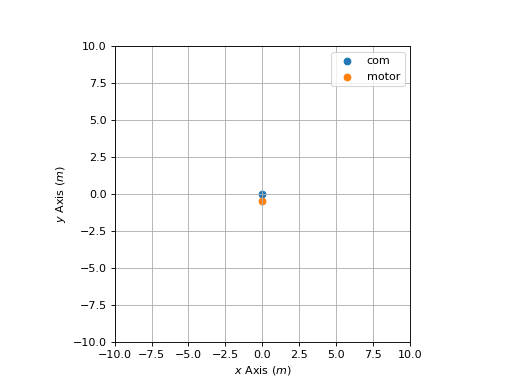

In [11]:
makeAnimation(q_list, dt)

gif_display = Image(filename='anim.gif')
display(gif_display)

### State feedback

In [12]:
systemDynamics = Matrix([x_1.diff(), x_2.diff(), theta.diff(), slns[x_1.diff().diff()], slns[x_2.diff().diff()], slns[theta.diff().diff()]])
systemDynamics.simplify()

In [13]:
x = [x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]
u = [u_1, u_2]

x_star = {x_1:0, x_2:0, theta:rad(-10), x_1.diff():0, x_2.diff():10, theta.diff():0}
u_star = {u_1:15, u_2:rad(0)}

systemDynamics.subs(x_star | u_star)

Matrix([
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           0],
[                                                                                                                              

In [14]:
A = systemDynamics.jacobian(x).subs(x_star | u_star)
A.simplify()
A = A.subs(params)

In [15]:
B = systemDynamics.jacobian(u).subs(x_star | u_star)
B.simplify()
B = B.subs(params)

In [16]:
systemDynamics.jacobian(u).subs(x_star | u_star)

Matrix([
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                0,                                                                                                                                                                                                                                                                                                                                                                                                            

In [17]:
Matrix([[B, A@B, (A@A)@B, (A@(A@A))@B, (A@(A@(A@A)))@B, (A@(A@(A@(A@A))))@B]]).rank()

6

In [18]:
Q = np.eye(len(x))*5
R = np.eye(len(u))
k, S, E = ct.lqr(A, B, Q, R)
k

array([[ 3.88289129e-01,  2.20209708e+00, -9.33272544e-15,
         5.08814526e-01,  2.88563057e+00, -8.40038107e-16],
       [ 2.20209708e+00, -3.88289129e-01, -1.78918592e+01,
         3.04384809e+00, -5.36712544e-01, -4.25367451e+00]])

In [19]:
(A-B@k).eigenvals()

{-1.1771263121583 - 0.386109520517084*I: 1,
 -1.1771263121583 + 0.386109520517084*I: 1,
 -0.999998195064642 + 7.37372695474274e-65*I: 1,
 -2.60414107042666 - 1.56182598271771*I: 1,
 -2.60414107042666 + 1.56182598271771*I: 1,
 -52.9685798163768: 1}

In [20]:
C = Matrix([[0, 0, 1, 0, 0, 0],
              [0, 0, 0, 0, 1, 0]])
(C @ (-(A-B@k)).inv() @ B).rank()

1

In [21]:
def odefun2(q, t, q_ref):
  qdot = np.zeros_like(q)
  qdot[:3] = q[3:]

  q_ref[2] = np.sin(t)

  u = -k@(q - q_ref*0)

  qdot[3:] = xddot(q, u[0], u[1]).squeeze()
  return qdot

In [22]:
dt = 1/(10*1000)
time = np.arange(0, 10, dt)
q0 = np.array([1, -1, 0, 0, 0, 0])

q_ref = np.array([0, 0, 0, 0, 1, 0])

q_list = odeint(odefun2, q0, time, args=(q_ref,))

In [23]:
q_list

array([[ 1.00000000e+00, -1.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 1.00000000e+00, -1.00000001e+00,  6.72007803e-09,
         6.72003065e-05, -1.06047539e-04,  1.34393890e-04],
       [ 1.00000001e+00, -1.00000002e+00,  2.68828902e-08,
         1.34442105e-04, -2.12087072e-04,  2.68857316e-04],
       ...,
       [ 2.27169248e+03,  1.28831539e+04, -1.74532705e-01,
         5.28686744e+03,  2.99834640e+04, -6.28777180e-06],
       [ 2.27222122e+03,  1.28861526e+04, -1.74532706e-01,
         5.28809802e+03,  2.99904430e+04, -9.44248174e-06],
       [ 2.27275010e+03,  1.28891520e+04, -1.74532707e-01,
         5.28932888e+03,  2.99974236e+04, -1.25867228e-05]])

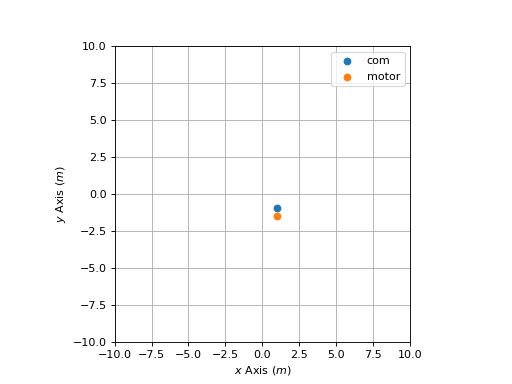

In [24]:
makeAnimation(q_list, dt, window_size=10)

gif_display = Image(filename='anim.gif')
display(gif_display)